# Rule-Based Sentiment Analysis of Video Comments

In [48]:
%pip install -q pandas matplotlib scikit-learn vaderSentiment


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [49]:
from pathlib import Path
import math
import re
import unicodedata

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import accuracy_score, confusion_matrix, precision_recall_fscore_support
from sklearn.model_selection import StratifiedKFold, train_test_split
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

SEED = 42
CLASS_ORDER = ['negative', 'neutral', 'positive']

def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / 'Trial2' / 'topics_train.csv').is_file():
            return candidate
    raise FileNotFoundError(
        'Could not locate Trial2/topics_train.csv. Run this notebook inside the project folder.'
    )

PROJECT_ROOT = find_project_root(Path.cwd().resolve())
SENTIMENT_DIR = PROJECT_ROOT / 'sentiment_analysis'
OUTPUT_DIR = SENTIMENT_DIR / 'outputs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TRAIN_PATH = PROJECT_ROOT / 'Trial2' / 'topics_train.csv'
HOLDOUT_PATH = PROJECT_ROOT / 'Trial2' / 'topics_holdout.csv'

print(f'Project root: {PROJECT_ROOT}')
print(f'Output directory: {OUTPUT_DIR}')

Project root: C:\Users\gerar\Downloads\CSE 15 DATA MINING\Midterm Act 1
Output directory: C:\Users\gerar\Downloads\CSE 15 DATA MINING\Midterm Act 1\sentiment_analysis\outputs


## 1. Load topic-annotated comments

The two topic output files contain the selected comments and their LDA/BERTopic labels. The files are combined so topic-level sentiment analysis covers both topic-modeling partitions. A separate sentiment text is built from each original comment so negation words can be kept while emojis, punctuation, URLs, and mentions are removed. The English-language subset is used because both sentiment lexicons are English-oriented; comments tagged with other languages are excluded from scoring rather than treated as neutral.

In [ ]:
train_df = pd.read_csv(TRAIN_PATH)
holdout_df = pd.read_csv(HOLDOUT_PATH)
train_df['topic_model_partition'] = 'topic_train'
holdout_df['topic_model_partition'] = 'topic_holdout'
df = pd.concat([train_df, holdout_df], ignore_index=True)

required_columns = {
    'document_id', 'platform', 'original_text', 'lang', 'lda_label', 'bt_label'
}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f'Topic files are missing required columns: {sorted(missing_columns)}')

overlapping_ids = set(train_df['document_id']).intersection(holdout_df['document_id'])
if overlapping_ids:
    raise ValueError(f'{len(overlapping_ids)} document IDs occur in both topic partitions.')

df['original_text'] = df['original_text'].fillna('').astype(str).str.strip()
df = df.loc[(df['lang'].eq('en')) & df['original_text'].ne('')].copy()
df = df.reset_index(drop=True)
if df.empty:
    raise ValueError('No non-empty English comments were found in the topic output files.')

NEGATION_EXPANSIONS = {
    "can't": 'can not', "cannot": 'can not', "couldn't": 'could not',
    "didn't": 'did not', "doesn't": 'does not', "don't": 'do not',
    "hadn't": 'had not', "hasn't": 'has not', "haven't": 'have not',
    "isn't": 'is not', "mightn't": 'might not', "mustn't": 'must not',
    "needn't": 'need not', "shouldn't": 'should not', "wasn't": 'was not',
    "weren't": 'were not', "won't": 'will not', "wouldn't": 'would not',
    "shan't": 'shall not', "ain't": 'not'
}
NEGATION_PATTERN = re.compile(
    r"\b(?:" + '|'.join(re.escape(form) for form in NEGATION_EXPANSIONS) + r")\b",
    flags=re.IGNORECASE
)

def make_sentiment_text(text: str) -> str:
    text = unicodedata.normalize('NFKC', text).lower().replace('’', "'")
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
    text = re.sub(r'@\w+', ' ', text)
    text = NEGATION_PATTERN.sub(
        lambda match: NEGATION_EXPANSIONS[match.group(0).lower()], text
    )
    text = re.sub(r'#([a-z0-9_]+)', r' \1 ', text)
    text = re.sub(r'[^a-z0-9_\s]', ' ', text)
    return re.sub(r'\s+', ' ', text).strip()

df['sentiment_text'] = df['original_text'].map(make_sentiment_text)
df = df.loc[df['sentiment_text'].ne('')].reset_index(drop=True)
assert 'not' in make_sentiment_text('This is not good')
assert 'not' in make_sentiment_text("I don't like it")
assert 'not' in make_sentiment_text("I can't agree")
assert make_sentiment_text('No, I do not agree') == 'no i do not agree'
assert make_sentiment_text('I love it') == 'i love it'

print(f'Topic-model comments: {len(train_df) + len(holdout_df):,}')
print(f'English sentiment comments scored: {len(df):,}')
print(f'Excluded non-English or empty comments: {len(train_df) + len(holdout_df) - len(df):,}')
print('\nTopic-model partitions:')
print(df['topic_model_partition'].value_counts())
print('\nPlatforms:')
print(df['platform'].value_counts())
display(df[['document_id', 'platform', 'sentiment_text', 'lda_label', 'bt_label']].head())

Topic-model comments: 1,288
English sentiment comments scored: 1,253
Excluded non-English or empty comments: 35

Topic-model partitions:
topic_model_partition
topic_train      1131
topic_holdout     122
Name: count, dtype: int64

Platforms:
platform
TikTok     970
YouTube    283
Name: count, dtype: int64


,document_id,platform,sentiment_text,lda_label,bt_label
0,DOC_005394,TikTok,that line broke my heart,"Cheating, Trust & Relationship Drama","Heartbreak Lines & ""Bring Me Back"" Requests"
1,DOC_005526,TikTok,mark is a girls man idc i loved him the most,"Clothing, Body Image & Why People Leave",Outliers / short generic comments
2,DOC_003280,TikTok,cool evry scene,Emotional Relatability & Life Reflections,Outliers / short generic comments
3,DOC_002207,TikTok,oya come backkk o,"Plot, Family & Series Commentary","Heartbreak Lines & ""Bring Me Back"" Requests"
4,DOC_001036,TikTok,just need the title plz,"Plot, Family & Series Commentary","Praise, Title & Next-Part Requests"


## 2. Rule-based sentiment classifier

The custom classifier counts positive and negative words, flips a word's polarity when a negator occurs in the preceding three tokens, and adjusts word scores for intensifiers and downtoners. The normalized score is mapped to three classes. Both this classifier and VADER receive the sentiment-specific text, which keeps negations and excludes emojis.

In [51]:
POSITIVE_WORDS = {
    'amazing', 'awesome', 'beautiful', 'best', 'brilliant', 'enjoy', 'enjoyed',
    'excellent', 'excited', 'favorite', 'fun', 'funny', 'glad', 'good', 'great',
    'happy', 'heartwarming', 'hope', 'impressive', 'interesting', 'love', 'loved',
    'lovely', 'nice', 'perfect', 'recommend', 'sweet', 'thank', 'thanks', 'wonderful',
    'wow', 'better', 'beautifully', 'adorable', 'cute', 'bravo', 'incredible',
    'enjoying', 'liked', 'like', 'charming', 'inspiring', 'favorite', 'support'
}
NEGATIVE_WORDS = {
    'annoying', 'angry', 'awful', 'bad', 'boring', 'confused', 'confusing',
    'cruel', 'disappointed', 'disappointing', 'hate', 'hated', 'horrible', 'hurt',
    'irritating', 'mad', 'mess', 'pain', 'poor', 'sad', 'stupid', 'tired',
    'tiring', 'terrible', 'ugly', 'unfortunately', 'waste', 'weird', 'worst',
    'wrong', 'sucks', 'dislike', 'unhappy', 'ridiculous', 'problem', 'fail', 'failed'
}
NEGATORS = {
    'not', 'no', 'never', 'neither', 'nor', 'hardly', 'barely', 'cannot',
    'dont', 'doesnt', 'didnt', 'isnt', 'wasnt', 'werent', 'wont', 'wouldnt',
    'shouldnt', 'couldnt', 'cant', 'aint'
}
INTENSIFIERS = {'very', 'really', 'extremely', 'so', 'absolutely', 'totally', 'super'}
DOWNTONERS = {'slightly', 'somewhat', 'rather', 'barely', 'little'}
def rule_sentiment(text: str) -> tuple[float, str]:
    tokens = re.findall('[a-z]+', text.lower())
    score = 0.0
    for index, token in enumerate(tokens):
        if token in POSITIVE_WORDS:
            word_score = 1.0
        elif token in NEGATIVE_WORDS:
            word_score = -1.0
        else:
            continue

        previous = tokens[max(0, index - 3):index]
        if any(word in NEGATORS for word in previous):
            word_score *= -1.0
        if any(word in INTENSIFIERS for word in previous):
            word_score *= 1.5
        elif any(word in DOWNTONERS for word in previous):
            word_score *= 0.5
        score += word_score

    normalized_score = score / math.sqrt(max(1, len(tokens)))
    if normalized_score > 0.15:
        label = 'positive'
    elif normalized_score < -0.15:
        label = 'negative'
    else:
        label = 'neutral'
    return normalized_score, label

assert rule_sentiment('This is not good')[1] == 'negative'
assert rule_sentiment('This is not bad')[1] == 'positive'
assert rule_sentiment(make_sentiment_text("I don't hate it"))[1] == 'positive'

rule_results = df['sentiment_text'].map(rule_sentiment)
df['rule_score'] = rule_results.map(lambda result: result[0])
df['rule_sentiment'] = rule_results.map(lambda result: result[1])

vader = SentimentIntensityAnalyzer()
df['vader_compound'] = df['sentiment_text'].map(
    lambda text: vader.polarity_scores(text)['compound']
)
df['vader_reference'] = pd.cut(
    df['vader_compound'],
    bins=[-1.000001, -0.05, 0.05, 1.000001],
    labels=['negative', 'neutral', 'positive'],
    include_lowest=True
).astype(str)

display(df[['sentiment_text', 'rule_score', 'rule_sentiment', 'vader_compound', 'vader_reference']].head(10))
print('Rule-based sentiment counts:')
display(df['rule_sentiment'].value_counts().reindex(CLASS_ORDER, fill_value=0).to_frame('comments'))

,sentiment_text,rule_score,rule_sentiment,vader_compound,vader_reference
0,that line broke my heart,0.000000,neutral,0.3400,positive
1,mark is a girls man idc i loved him the most,0.301511,positive,0.5994,positive
2,cool evry scene,0.000000,neutral,0.3182,positive
3,oya come backkk o,0.000000,neutral,0.0000,neutral
4,just need the title plz,0.000000,neutral,0.0772,positive
5,it said it was full movie but it finished with...,-0.229416,negative,-0.4782,negative
6,and mr demono everything except the actual nam...,0.000000,neutral,0.4215,positive
7,pls someone should bring me back,0.000000,neutral,0.0772,positive
8,my bf and i were crying during this scene tyle...,0.000000,neutral,-0.5812,negative
9,and it s not a superiority complex if i just w...,0.000000,neutral,0.3031,positive


Rule-based sentiment counts:


,comments
rule_sentiment,
negative,83
neutral,838
positive,332


## 3. 90/10 unseen-data evaluation

VADER supplies an independent lexicon-based **weak reference** because the dataset has no human sentiment labels. Its standard compound-score cutoffs are used: at or below -0.05 is negative, between -0.05 and 0.05 is neutral, and at or above 0.05 is positive. The custom rule classifier is compared with this reference on a stratified 10% holdout. Reported scores are agreement with VADER, not validated human-label performance.

Training partition: 1,127; unseen test partition: 126


,n_comments,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1
evaluation,,,,,,,,
90/10 unseen holdout,126,0.603,0.718,0.588,0.546,0.769,0.603,0.592


,class,precision,recall,f1,support
0,negative,0.750,0.214,0.333,28
1,neutral,0.434,1.000,0.605,36
2,positive,0.971,0.548,0.701,62


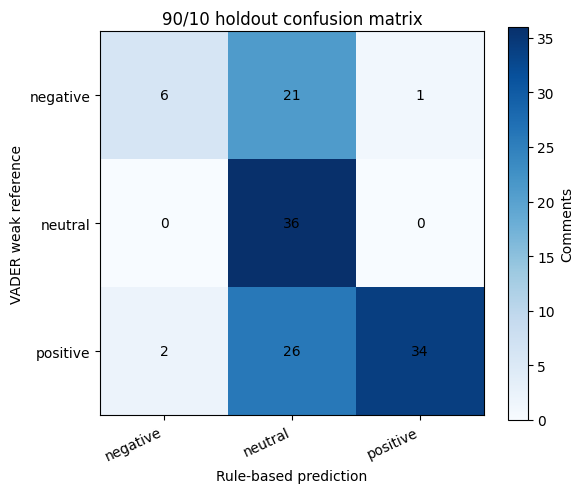

In [52]:
reference = df['vader_reference'].astype(str)
predicted = df['rule_sentiment'].astype(str)
class_counts = reference.value_counts()
if class_counts.min() < 10:
    raise ValueError(
        'At least 10 comments per VADER reference class are required for stratified 10-fold validation.'
    )

row_indices = pd.RangeIndex(len(df))
train_indices, test_indices = train_test_split(
    row_indices,
    test_size=0.10,
    random_state=SEED,
    stratify=reference
)

def evaluate_agreement(y_true: pd.Series, y_pred: pd.Series, name: str) -> tuple[dict, pd.DataFrame]:
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, y_pred, labels=CLASS_ORDER, zero_division=0
    )
    macro_precision, macro_recall, macro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=CLASS_ORDER, average='macro', zero_division=0
    )
    weighted_precision, weighted_recall, weighted_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=CLASS_ORDER, average='weighted', zero_division=0
    )
    summary = {
        'evaluation': name,
        'n_comments': len(y_true),
        'accuracy': accuracy_score(y_true, y_pred),
        'macro_precision': macro_precision,
        'macro_recall': macro_recall,
        'macro_f1': macro_f1,
        'weighted_precision': weighted_precision,
        'weighted_recall': weighted_recall,
        'weighted_f1': weighted_f1
    }
    per_class = pd.DataFrame({
        'class': CLASS_ORDER,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'support': support
    })
    return summary, per_class

holdout_summary, holdout_per_class = evaluate_agreement(
    reference.iloc[test_indices], predicted.iloc[test_indices], '90/10 unseen holdout'
)
print(f'Training partition: {len(train_indices):,}; unseen test partition: {len(test_indices):,}')
display(pd.DataFrame([holdout_summary]).set_index('evaluation').round(3))
display(holdout_per_class.round(3))

holdout_matrix = confusion_matrix(
    reference.iloc[test_indices], predicted.iloc[test_indices], labels=CLASS_ORDER
)
fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(holdout_matrix, cmap='Blues')
ax.set_xticks(range(len(CLASS_ORDER)), CLASS_ORDER, rotation=25, ha='right')
ax.set_yticks(range(len(CLASS_ORDER)), CLASS_ORDER)
ax.set_xlabel('Rule-based prediction')
ax.set_ylabel('VADER weak reference')
ax.set_title('90/10 holdout confusion matrix')
for row in range(len(CLASS_ORDER)):
    for column in range(len(CLASS_ORDER)):
        ax.text(column, row, str(holdout_matrix[row, column]), ha='center', va='center')
fig.colorbar(image, ax=ax, label='Comments')
fig.tight_layout()
plt.show()

## 4. Stratified 10-fold validation

The rule classifier is deterministic and has no training step. Ten-fold validation therefore reports out-of-fold agreement with the VADER weak reference on each held-out fold. The table gives mean and standard deviation across folds, along with metrics aggregated over all out-of-fold predictions. Human-annotated labels are needed to interpret these values as true sentiment-classification performance.

In [53]:
fold_rows = []
out_of_fold_predictions = pd.Series(index=df.index, dtype='object')
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
for fold_number, (_, fold_test_indices) in enumerate(cv.split(df, reference), start=1):
    y_true = reference.iloc[fold_test_indices]
    y_pred = predicted.iloc[fold_test_indices]
    out_of_fold_predictions.iloc[fold_test_indices] = y_pred.to_numpy()
    fold_summary, _ = evaluate_agreement(y_true, y_pred, f'fold_{fold_number}')
    fold_summary['fold'] = fold_number
    fold_rows.append(fold_summary)

fold_metrics = pd.DataFrame(fold_rows)
cv_mean = fold_metrics[['accuracy', 'macro_precision', 'macro_recall', 'macro_f1']].mean()
cv_std = fold_metrics[['accuracy', 'macro_precision', 'macro_recall', 'macro_f1']].std(ddof=1)
cv_summary = pd.DataFrame({'mean': cv_mean, 'std': cv_std})
overall_oof_summary, overall_oof_per_class = evaluate_agreement(
    reference, out_of_fold_predictions.astype(str), '10-fold out-of-fold aggregate'
)

print('10-fold metrics (mean and standard deviation):')
display(cv_summary.round(3))
print('Aggregate out-of-fold metrics:')
display(pd.DataFrame([overall_oof_summary]).set_index('evaluation').round(3))
display(overall_oof_per_class.round(3))
display(fold_metrics[['fold', 'n_comments', 'accuracy', 'macro_precision', 'macro_recall', 'macro_f1']].round(3))

10-fold metrics (mean and standard deviation):


,mean,std
accuracy,0.586,0.043
macro_precision,0.740,0.069
macro_recall,0.578,0.031
macro_f1,0.544,0.038


Aggregate out-of-fold metrics:


,n_comments,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1
evaluation,,,,,,,,
10-fold out-of-fold aggregate,1253,0.586,0.743,0.578,0.547,0.777,0.586,0.581


,class,precision,recall,f1,support
0,negative,0.867,0.255,0.395,282
1,neutral,0.414,0.964,0.579,360
2,positive,0.949,0.516,0.668,611


,fold,n_comments,accuracy,macro_precision,macro_recall,macro_f1
0,1,126,0.571,0.746,0.565,0.535
1,2,126,0.595,0.794,0.591,0.564
2,3,126,0.587,0.596,0.545,0.485
3,4,125,0.648,0.810,0.611,0.571
4,5,125,0.520,0.666,0.545,0.512
5,6,125,0.608,0.798,0.587,0.554
6,7,125,0.584,0.752,0.593,0.561
7,8,125,0.520,0.683,0.529,0.489
8,9,125,0.640,0.780,0.625,0.598
9,10,125,0.584,0.772,0.592,0.574


## 5. Sentiment by platform and topic

The LDA topics are the primary topic-level comparison because they provide the nine interpretable categories selected in the topic-modeling analysis. BERTopic is also summarized to compare its cluster view; the BERTopic outlier group is retained and identified as such rather than silently removed. Percentages within each group make platforms and topics of different sizes comparable.

,comments,percent
rule_sentiment,,
negative,83,6.62
neutral,838,66.88
positive,332,26.50


By platform:


rule_sentiment,negative,neutral,positive,negative_percent,neutral_percent,positive_percent
platform,,,,,,
YouTube,23,136,124,8.13,48.06,43.82
TikTok,60,702,208,6.19,72.37,21.44


By LDA topic:


rule_sentiment,negative,neutral,positive,negative_percent,neutral_percent,positive_percent
lda_label,,,,,,
Love Story Appreciation & Wanting the Rest,9,106,83,4.55,53.54,41.92
"Clothing, Body Image & Why People Leave",16,64,44,12.90,51.61,35.48
Emotional Relatability & Life Reflections,8,90,48,5.48,61.64,32.88
"Names, Actors & Personal Experiences",7,97,45,4.70,65.10,30.20
"Plot, Family & Series Commentary",4,98,38,2.86,70.00,27.14
Channel Promos & Straight-to-the-Point Praise,4,86,29,3.36,72.27,24.37
"Cheating, Trust & Relationship Drama",19,103,19,13.48,73.05,13.48
"""Bring Me Back"" Requests & Scene Reactions",4,103,14,3.31,85.12,11.57
Gender Expression & Where to Watch,12,91,12,10.43,79.13,10.43


By BERTopic topic (including outliers):


rule_sentiment,negative,neutral,positive,negative_percent,neutral_percent,positive_percent
bt_label,,,,,,
Birthday Wishes,0,2,9,0.00,18.18,81.82
"Praise, Title & Next-Part Requests",9,124,90,4.04,55.61,40.36
Crying Over Scenes & Character Reactions,16,74,60,10.67,49.33,40.00
Outliers / short generic comments,19,240,72,5.74,72.51,21.75
"Heartbreak Lines & ""Bring Me Back"" Requests",11,205,55,4.06,75.65,20.30
"Faith, Gods & Encouragement",7,71,18,7.29,73.96,18.75
Judging Characters & Their Names,15,50,15,18.75,62.50,18.75
Fish Jokes & Puns,0,11,2,0.00,84.62,15.38
"Gender Identity, Clothing & Body Image",6,50,10,9.09,75.76,15.15


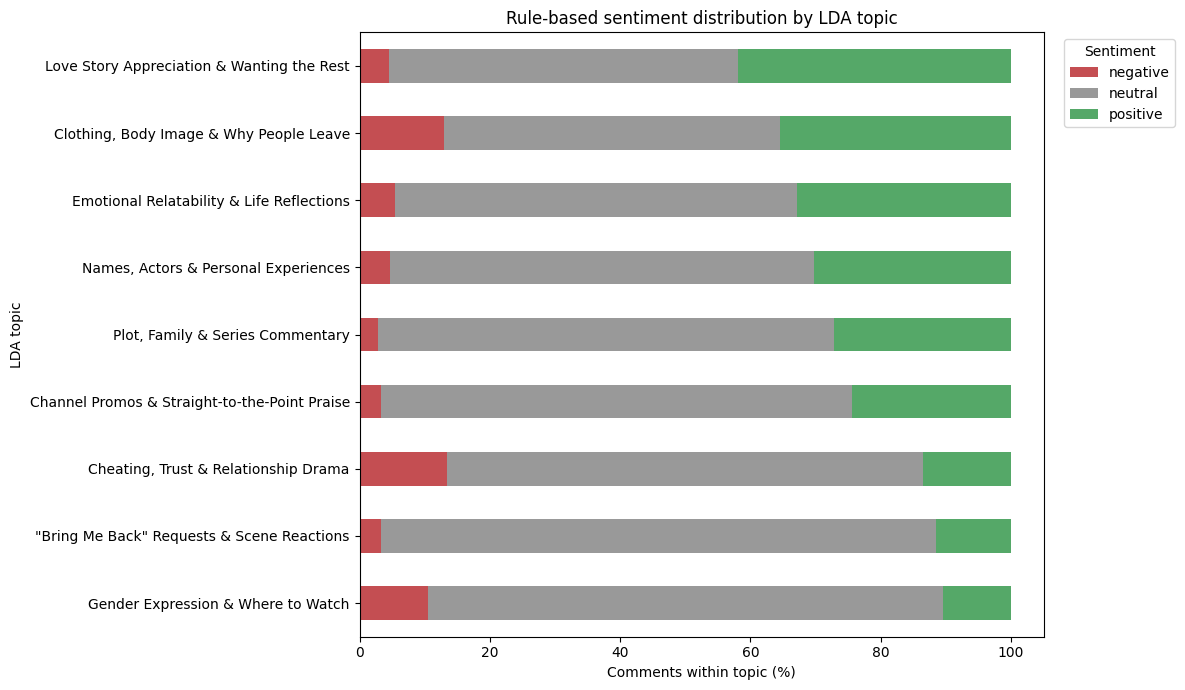

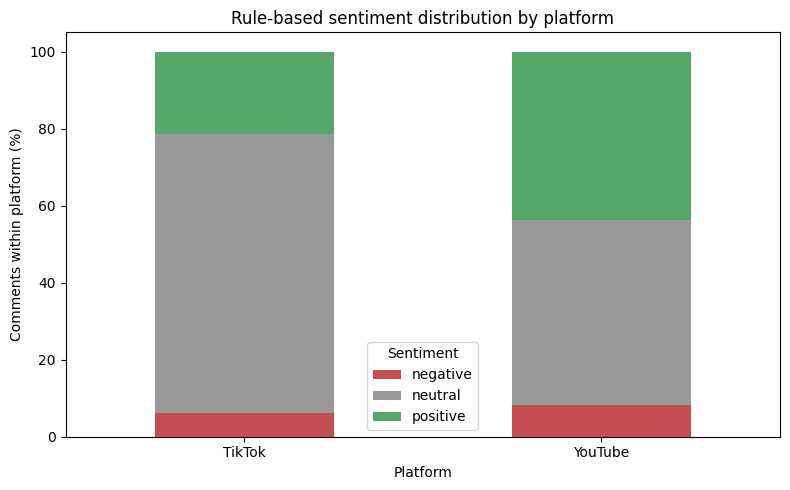

In [54]:
sentiment_counts = df['rule_sentiment'].value_counts().reindex(CLASS_ORDER, fill_value=0)
sentiment_percent = (sentiment_counts / len(df) * 100).rename('percent')
display(pd.concat([sentiment_counts.rename('comments'), sentiment_percent], axis=1).round(2))

def sentiment_breakdown(group_column: str) -> pd.DataFrame:
    counts = pd.crosstab(df[group_column], df['rule_sentiment']).reindex(columns=CLASS_ORDER, fill_value=0)
    percentages = counts.div(counts.sum(axis=1).replace(0, 1), axis=0) * 100
    return counts.join(percentages, rsuffix='_percent').sort_values(
        'positive_percent', ascending=False
    )

platform_breakdown = sentiment_breakdown('platform')
lda_breakdown = sentiment_breakdown('lda_label')
bertopic_breakdown = sentiment_breakdown('bt_label')
print('By platform:')
display(platform_breakdown.round(2))
print('By LDA topic:')
display(lda_breakdown.round(2))
print('By BERTopic topic (including outliers):')
display(bertopic_breakdown.round(2))

topic_percentages = pd.crosstab(
    df['lda_label'], df['rule_sentiment'], normalize='index'
).reindex(columns=CLASS_ORDER, fill_value=0) * 100
topic_percentages = topic_percentages.sort_values('positive', ascending=True)
ax = topic_percentages.plot(
    kind='barh', stacked=True, figsize=(12, 7),
    color={'negative': '#c44e52', 'neutral': '#999999', 'positive': '#55a868'}
)
ax.set_xlabel('Comments within topic (%)')
ax.set_ylabel('LDA topic')
ax.set_title('Rule-based sentiment distribution by LDA topic')
ax.legend(title='Sentiment', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

platform_percentages = pd.crosstab(
    df['platform'], df['rule_sentiment'], normalize='index'
).reindex(columns=CLASS_ORDER, fill_value=0) * 100
ax = platform_percentages.plot(
    kind='bar', stacked=True, figsize=(8, 5),
    color={'negative': '#c44e52', 'neutral': '#999999', 'positive': '#55a868'}
)
ax.set_ylabel('Comments within platform (%)')
ax.set_xlabel('Platform')
ax.set_title('Rule-based sentiment distribution by platform')
ax.legend(title='Sentiment')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 6. Save outputs and interpret results

The prediction export retains the sentiment-specific text used for scoring, along with platform, topic labels, custom-rule score, VADER score, and both sentiment labels. Original comments and emojis are not included in the export. Topic and platform summaries use custom-rule predictions. Interpret small differences cautiously: lexicons can miss sarcasm, context, mixed-language phrasing, character names, and sentiment expressed through plot description rather than opinion.

In [55]:
prediction_columns = [
    'document_id', 'platform', 'sentiment_text', 'topic_model_partition',
    'lda_label', 'bt_label', 'rule_score', 'rule_sentiment',
    'vader_compound', 'vader_reference'
]
predictions_path = OUTPUT_DIR / 'sentiment_predictions.csv'
lda_path = OUTPUT_DIR / 'sentiment_by_lda_topic.csv'
bertopic_path = OUTPUT_DIR / 'sentiment_by_bertopic_topic.csv'
platform_path = OUTPUT_DIR / 'sentiment_by_platform.csv'
metrics_path = OUTPUT_DIR / 'sentiment_evaluation_metrics.csv'

df[prediction_columns].to_csv(predictions_path, index=False)
lda_breakdown.to_csv(lda_path)
bertopic_breakdown.to_csv(bertopic_path)
platform_breakdown.to_csv(platform_path)
metrics = pd.concat([
    pd.DataFrame([holdout_summary]),
    pd.DataFrame([overall_oof_summary])
], ignore_index=True)
metrics.to_csv(metrics_path, index=False)

for output_path in [predictions_path, lda_path, bertopic_path, platform_path, metrics_path]:
    print(f'Saved: {output_path}')

print(
    'Conclusion guide: identify the most positive and negative LDA topics from the '
    'within-topic percentages, compare YouTube and TikTok cautiously, and describe '
    'evaluation scores as agreement with VADER. A human-annotated sample is required '
    'before claiming ground-truth model accuracy.'
)

Saved: C:\Users\gerar\Downloads\CSE 15 DATA MINING\Midterm Act 1\sentiment_analysis\outputs\sentiment_predictions.csv
Saved: C:\Users\gerar\Downloads\CSE 15 DATA MINING\Midterm Act 1\sentiment_analysis\outputs\sentiment_by_lda_topic.csv
Saved: C:\Users\gerar\Downloads\CSE 15 DATA MINING\Midterm Act 1\sentiment_analysis\outputs\sentiment_by_bertopic_topic.csv
Saved: C:\Users\gerar\Downloads\CSE 15 DATA MINING\Midterm Act 1\sentiment_analysis\outputs\sentiment_by_platform.csv
Saved: C:\Users\gerar\Downloads\CSE 15 DATA MINING\Midterm Act 1\sentiment_analysis\outputs\sentiment_evaluation_metrics.csv
Conclusion guide: identify the most positive and negative LDA topics from the within-topic percentages, compare YouTube and TikTok cautiously, and describe evaluation scores as agreement with VADER. A human-annotated sample is required before claiming ground-truth model accuracy.
